# Lectura de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/digit/train.csv')

In [2]:
print("El conjunto de datos tiene {} filas y {} columnas".format(df.shape[0],df.shape[1]))
df.head()

El conjunto de datos tiene 42000 filas y 785 columnas


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
y = df.label.values
x = df.drop("label",axis=1)

In [4]:
x = x.values
x = x / 255.0

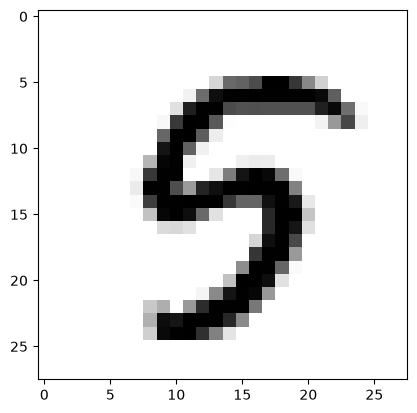

In [5]:
number = x[8].reshape(28,28)
plt.imshow(number, cmap=plt.cm.binary)
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.30, random_state=103)

# Construyendo y entrenando la NN

In [7]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import SGD

model = keras.Sequential([
    keras.layers.Dense(16, activation='sigmoid',input_shape=(784,)),
    keras.layers.Dense(16, activation='sigmoid'),
    keras.layers.Dense(10, activation='softmax')
])

sgd = SGD(lr = 0.1)
model.compile(optimizer = sgd, loss = 'sparse_categorical_crossentropy', metrics =["sparse_categorical_accuracy"])
model.fit(x_train, y_train, epochs = 50, batch_size = 100)

2026-11-10 23:28:59.188756: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-10 23:28:59.365663: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-10 23:28:59.650570: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-10 23:28:59.650627: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-10 23:28:59.669640: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

Epoch 1/50
294/294 [==============================] - 1s 2ms/step - loss: 2.3428 - sparse_categorical_accuracy: 0.1101
Epoch 2/50
294/294 [==============================] - 1s 2ms/step - loss: 2.2825 - sparse_categorical_accuracy: 0.1138
Epoch 3/50
294/294 [==============================] - 1s 2ms/step - loss: 2.2699 - sparse_categorical_accuracy: 0.1342
Epoch 4/50
294/294 [==============================] - 1s 2ms/step - loss: 2.2586 - sparse_categorical_accuracy: 0.1418
Epoch 5/50
294/294 [==============================] - 1s 2ms/step - loss: 2.2456 - sparse_categorical_accuracy: 0.2340
Epoch 6/50
294/294 [==============================] - 1s 2ms/step - loss: 2.2301 - sparse_categorical_accuracy: 0.2854
Epoch 7/50
294/294 [==============================] - 1s 2ms/step - loss: 2.2114 - sparse_categorical_accuracy: 0.3563
Epoch 8/50
294/294 [==============================] - 1s 2ms/step - loss: 2.1888 - sparse_categorical_accuracy: 0.4032
Epoch 9/50
294/294 [============================

In [8]:
test_loss = model.evaluate(x_test, y_test)

print('Test loss:', test_loss)

394/394 [==============================] - 1s 2ms/step - loss: 0.6772 - sparse_categorical_accuracy: 0.8385
Test loss: [0.6771790385246277, 0.8384920358657837]


In [9]:
model.save("my_model.h5")
np.save("xtest.npy", x_test)
np.save("ytest.npy", y_test)

/home/rbarrien/proyectos/academia/deep_learning_anahuac/venv/lib/python3.11/site-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(
